In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:


df = pd.read_csv(r'Student_Performance.csv')


In [3]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [4]:
df.shape

(10000, 6)

In [5]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 490.6 KB


In [7]:
df.isnull().sum()

Hours Studied                          0
Previous Scores                        0
Extracurricular Activities          1572
Sleep Hours                            0
Sample Question Papers Practiced    2856
Performance Index                      0
dtype: int64

In [8]:
from sklearn import impute
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
df[['Extracurricular Activities']]=imputer.fit_transform(df[['Extracurricular Activities']])


(array([693., 701., 660., 738., 670., 730., 759., 725., 738., 730.]),
 array([0. , 0.9, 1.8, 2.7, 3.6, 4.5, 5.4, 6.3, 7.2, 8.1, 9. ]),
 <BarContainer object of 10 artists>)

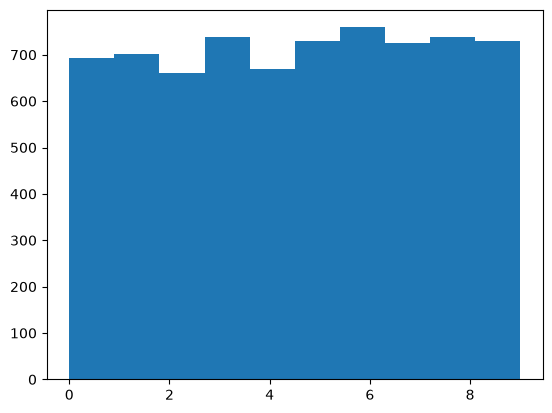

In [9]:
plt.hist(df['Sample Question Papers Practiced'])

In [10]:
imputer=SimpleImputer(missing_values=np.nan,strategy='mean')
df[['Sample Question Papers Practiced']]=imputer.fit_transform(df[['Sample Question Papers Practiced']])

In [11]:
df.isnull().sum().sum()

0

In [12]:
df.duplicated().sum()

151

In [13]:
df.drop_duplicates(inplace=True)

In [14]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['Extracurricular Activities']=le.fit_transform(df['Extracurricular Activities'])
df.head()


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1.0,91
1,4,82,0,4,2.0,65
2,8,51,1,7,2.0,45
3,5,52,1,5,2.0,36
4,7,75,0,8,5.0,66


<Axes: xlabel='Sample Question Papers Practiced', ylabel='Performance Index'>

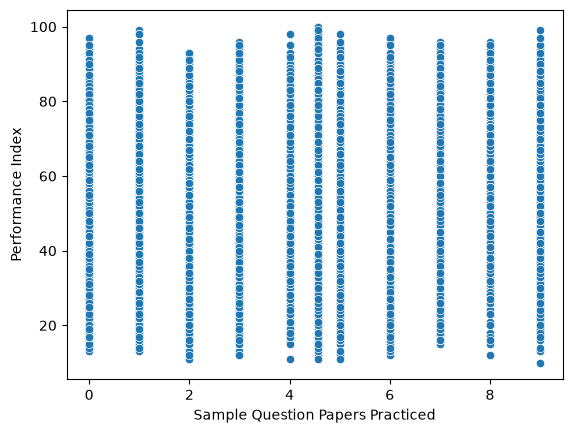

In [15]:
sns.scatterplot(x='Sample Question Papers Practiced',y='Performance Index',data=df)

In [16]:
df['Sample Question Papers Practiced'].corr(
    df['Performance Index']
)

0.030805500952450365

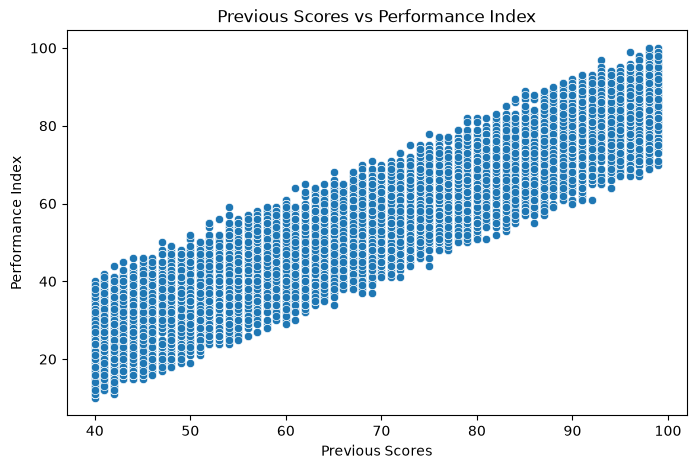

In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Previous Scores', y='Performance Index', data=df)
plt.title('Previous Scores vs Performance Index')
plt.show()

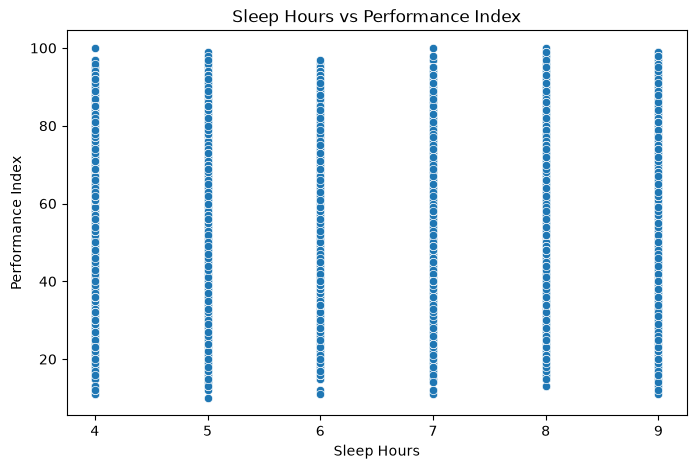

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Sleep Hours', y='Performance Index', data=df)
plt.title('Sleep Hours vs Performance Index')
plt.show()

In [19]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
df[['Previous Scores']]=scaler.fit_transform(df[['Previous Scores']])
df

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,1.000000,1,9,1.0,91
1,4,0.711864,0,4,2.0,65
2,8,0.186441,1,7,2.0,45
3,5,0.203390,1,5,2.0,36
4,7,0.593220,0,8,5.0,66
...,...,...,...,...,...,...
9995,1,0.152542,1,4,2.0,23
9996,7,0.406780,1,8,5.0,58
9997,6,0.728814,1,8,5.0,74
9998,9,0.966102,1,7,0.0,95


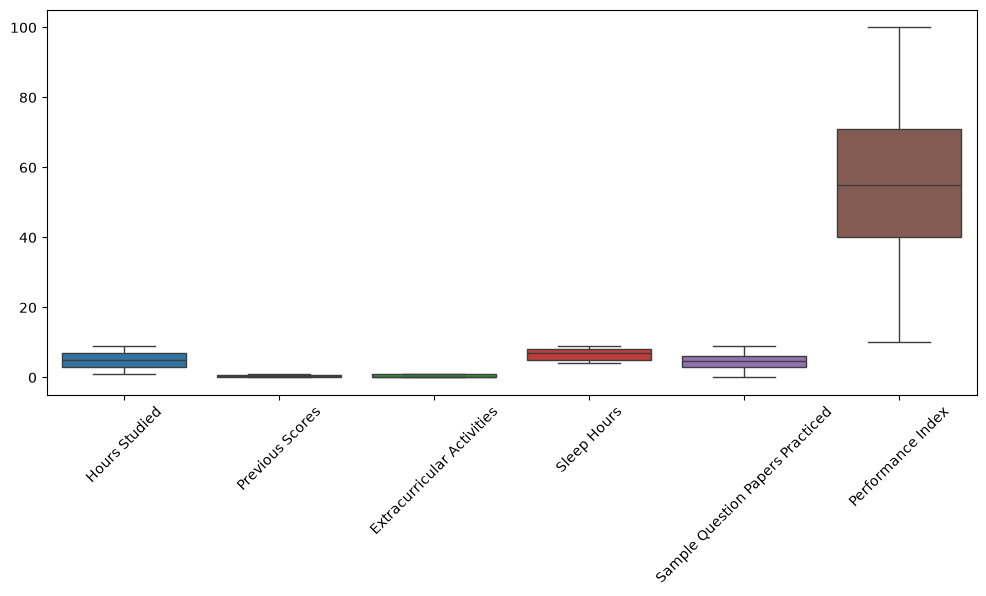

In [20]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df.select_dtypes(include='number'))
plt.xticks(rotation=45)
plt.show()

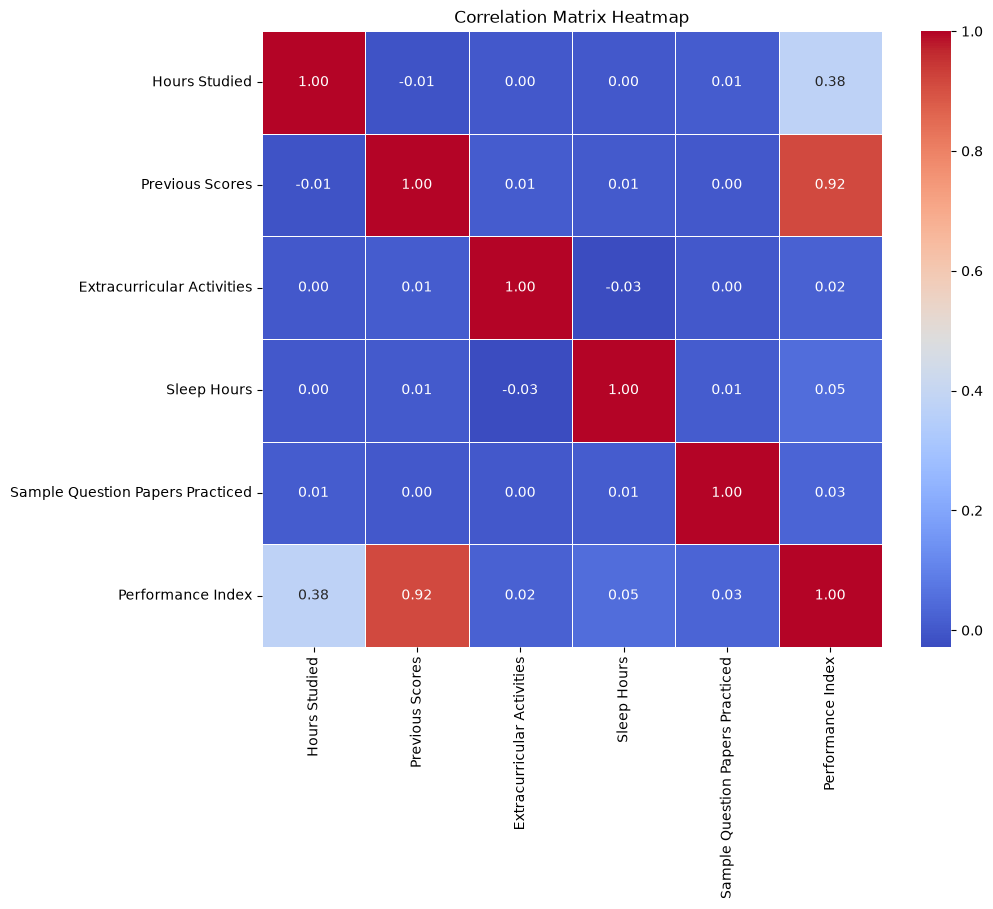

In [21]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

In [22]:
X=df.drop(columns=['Performance Index'])
y=df['Performance Index']

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X = df.drop(columns=['Performance Index'])
y = df['Performance Index']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=100
)

my_scaler = MinMaxScaler(feature_range=(0, 1))

X_train = my_scaler.fit_transform(X_train)

X_test = my_scaler.transform(X_test)



`%pip install -q xgboost lightgbm catboost`

In [24]:
from tqdm import tqdm

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor


C:\Users\Ahmed\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [25]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5, metric='minkowski', p=1),  # minkowski, euclidean, manhattan
    "SVM": SVR(kernel='linear', C=100, gamma=1),  # kernel='rbf' / 'poly', degree=4 / 'sigmoid'
    "Decision Tree": DecisionTreeRegressor(criterion='squared_error', max_depth=10),
    "Random Forest": RandomForestRegressor(n_estimators=50, criterion='squared_error', max_depth=10),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error', max_depth=10),
                                n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
}


In [26]:
# Metrics function (same as the Ames notebook)
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2


## 3) Train every model 

In [27]:
errors = {}
fitted_models = {}

for model_name, model in tqdm(models.items()):
    model.fit(X_train, y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R_Train,
        "R2 Test": R_Test
    }
    fitted_models[model_name] = model



  0%|          | 0/15 [00:00<?, ?it/s]


 27%|██▋       | 4/15 [00:00<00:01,  9.23it/s]


 33%|███▎      | 5/15 [00:13<00:35,  3.55s/it]


 47%|████▋     | 7/15 [00:14<00:18,  2.26s/it]


 53%|█████▎    | 8/15 [00:20<00:20,  2.98s/it]


 60%|██████    | 9/15 [00:22<00:17,  2.84s/it]

... (4 outputs left out)


 93%|█████████▎| 14/15 [00:38<00:02,  2.89s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000373 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 88
[LightGBM] [Info] Number of data points in the train set: 7879, number of used features: 5
[LightGBM] [Info] Start training from score 55.252951



100%|██████████| 15/15 [00:38<00:00,  2.15s/it]


100%|██████████| 15/15 [00:38<00:00,  2.56s/it]

### Voting Regressors 

In [28]:
# Individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Simple averaging
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)

for name, mdl in [("Voting", model1), ("Simple Voting", model2), ("Weighted Voting", model3)]:
    MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(mdl, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(mdl, X_test, y_test)

    errors[name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train,
        "R2 Test": R2_Test
    }
    fitted_models[name] = mdl


### Stacking 

In [29]:
# Base models for stacking
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# Meta-model
meta_regressor = XGBRegressor()

stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)

stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
    "MAE Train": MAE_Train,
    "MAE Test": MAE_Test,
    "MSE Train": MSE_Train,
    "MSE Test": MSE_Test,
    "RMSE Train": RMSE_Train,
    "RMSE Test": RMSE_Test,
    "R2 Train": R2_Train,
    "R2 Test": R2_Test
}
fitted_models["Stacking"] = stacking_regressor


## 4) Comparison table (all models)

In [30]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test", ascending=False)
errors_df


,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Linear Regression,1.638824,1.680140,4.248736,4.501355,2.061246,2.121640,0.988415,0.988147
Ridge,1.638869,1.680499,4.249499,4.501684,2.061431,2.121717,0.988413,0.988146
SVM,1.638697,1.681859,4.250097,4.509798,2.061576,2.123629,0.988412,0.988124
CatBoost,1.626883,1.698776,4.190016,4.643317,2.046953,2.154836,0.988576,0.987773
HistGradientBoosting,1.531112,1.717643,3.689252,4.763229,1.920743,2.182482,0.989941,0.987457
LightGBM,1.531112,1.717668,3.689252,4.764303,1.920743,2.182728,0.989941,0.987454
GradientBoosting,1.648821,1.719867,4.265230,4.827329,2.065243,2.197118,0.988370,0.987288
XGBoost,1.455375,1.735069,3.346032,4.871838,1.829216,2.207224,0.990877,0.987171
Stacking,1.623793,1.822932,4.350854,5.318443,2.085870,2.306175,0.988137,0.985995
Random Forest,1.317674,1.838783,2.714207,5.375089,1.647485,2.318424,0.992599,0.985846


## 5) Best model 



In [31]:
best_model_name = errors_df.index[0]
best_model = fitted_models[best_model_name]

print("=" * 65)
print(f"Best Model: {best_model_name}")
print("=" * 65)
print(f"{'Metric':<8}{'Train':>18}{'Test':>18}")
print("-" * 65)
for metric in ["MAE", "MSE", "RMSE", "R2"]:
    print(f"{metric:<8}"
          f"{errors_df.loc[best_model_name, metric + ' Train']:>18.4f}"
          f"{errors_df.loc[best_model_name, metric + ' Test']:>18.4f}")
print("=" * 65)


Best Model: Linear Regression
Metric               Train              Test
-----------------------------------------------------------------
MAE                 1.6388            1.6801
MSE                 4.2487            4.5014
RMSE                2.0612            2.1216
R2                  0.9884            0.9881


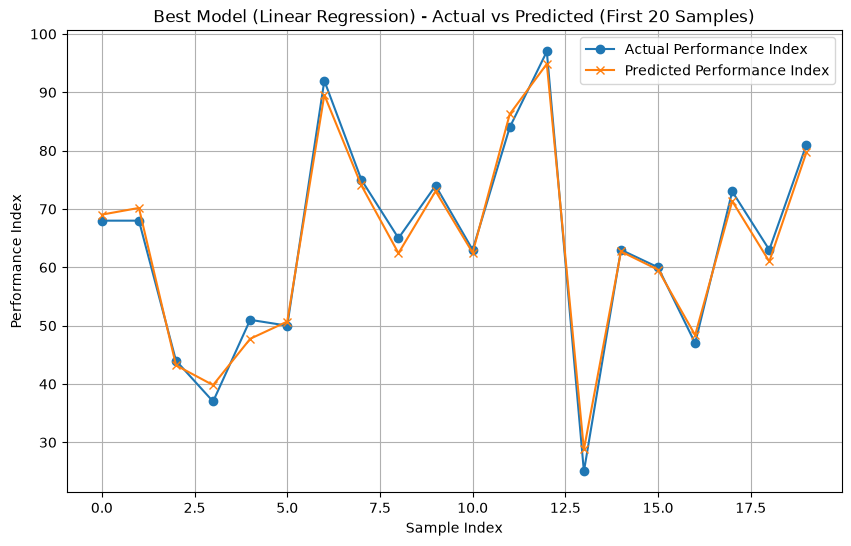

In [32]:
# Actual vs Predicted for the best model only (first 20 test samples)
y_test_plot = y_test.values[:20]
y_pred_plot = best_model.predict(X_test[:20])

plt.figure(figsize=(10, 6))
plt.plot(range(20), y_test_plot, label='Actual Performance Index', marker='o')
plt.plot(range(20), y_pred_plot, label='Predicted Performance Index', marker='x')
plt.xlabel('Sample Index')
plt.ylabel('Performance Index')
plt.title(f'Best Model ({best_model_name}) - Actual vs Predicted (First 20 Samples)')
plt.legend()
plt.grid()
plt.show()


## 6) Quick comparison charts

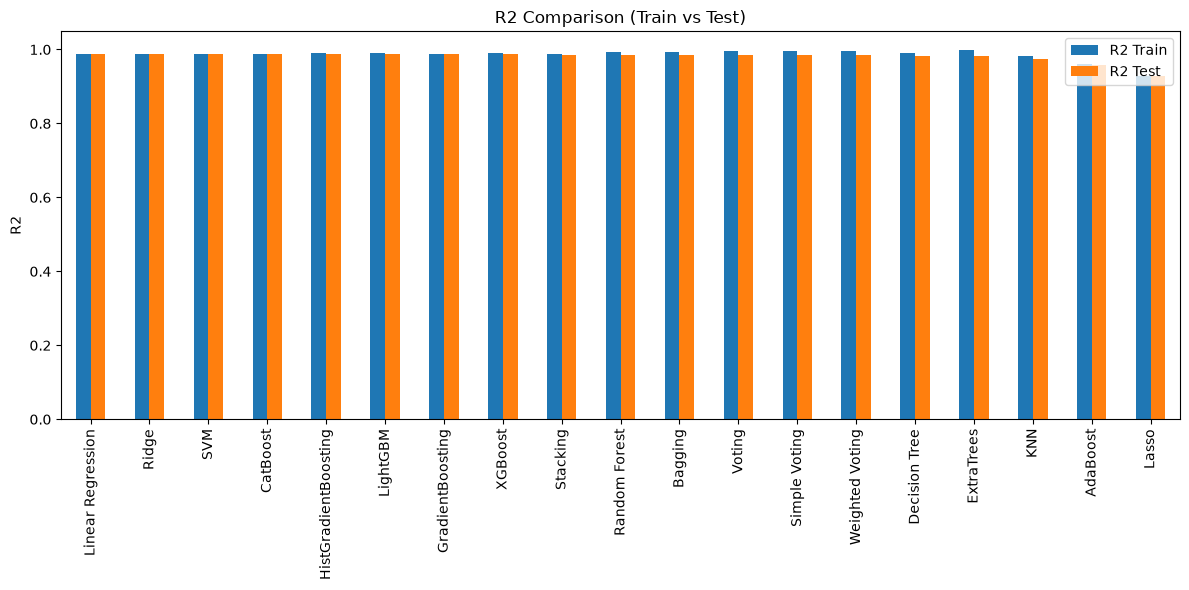

In [33]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12, 6))
plt.title('R2 Comparison (Train vs Test)')
plt.ylabel('R2')
plt.tight_layout()
plt.show()


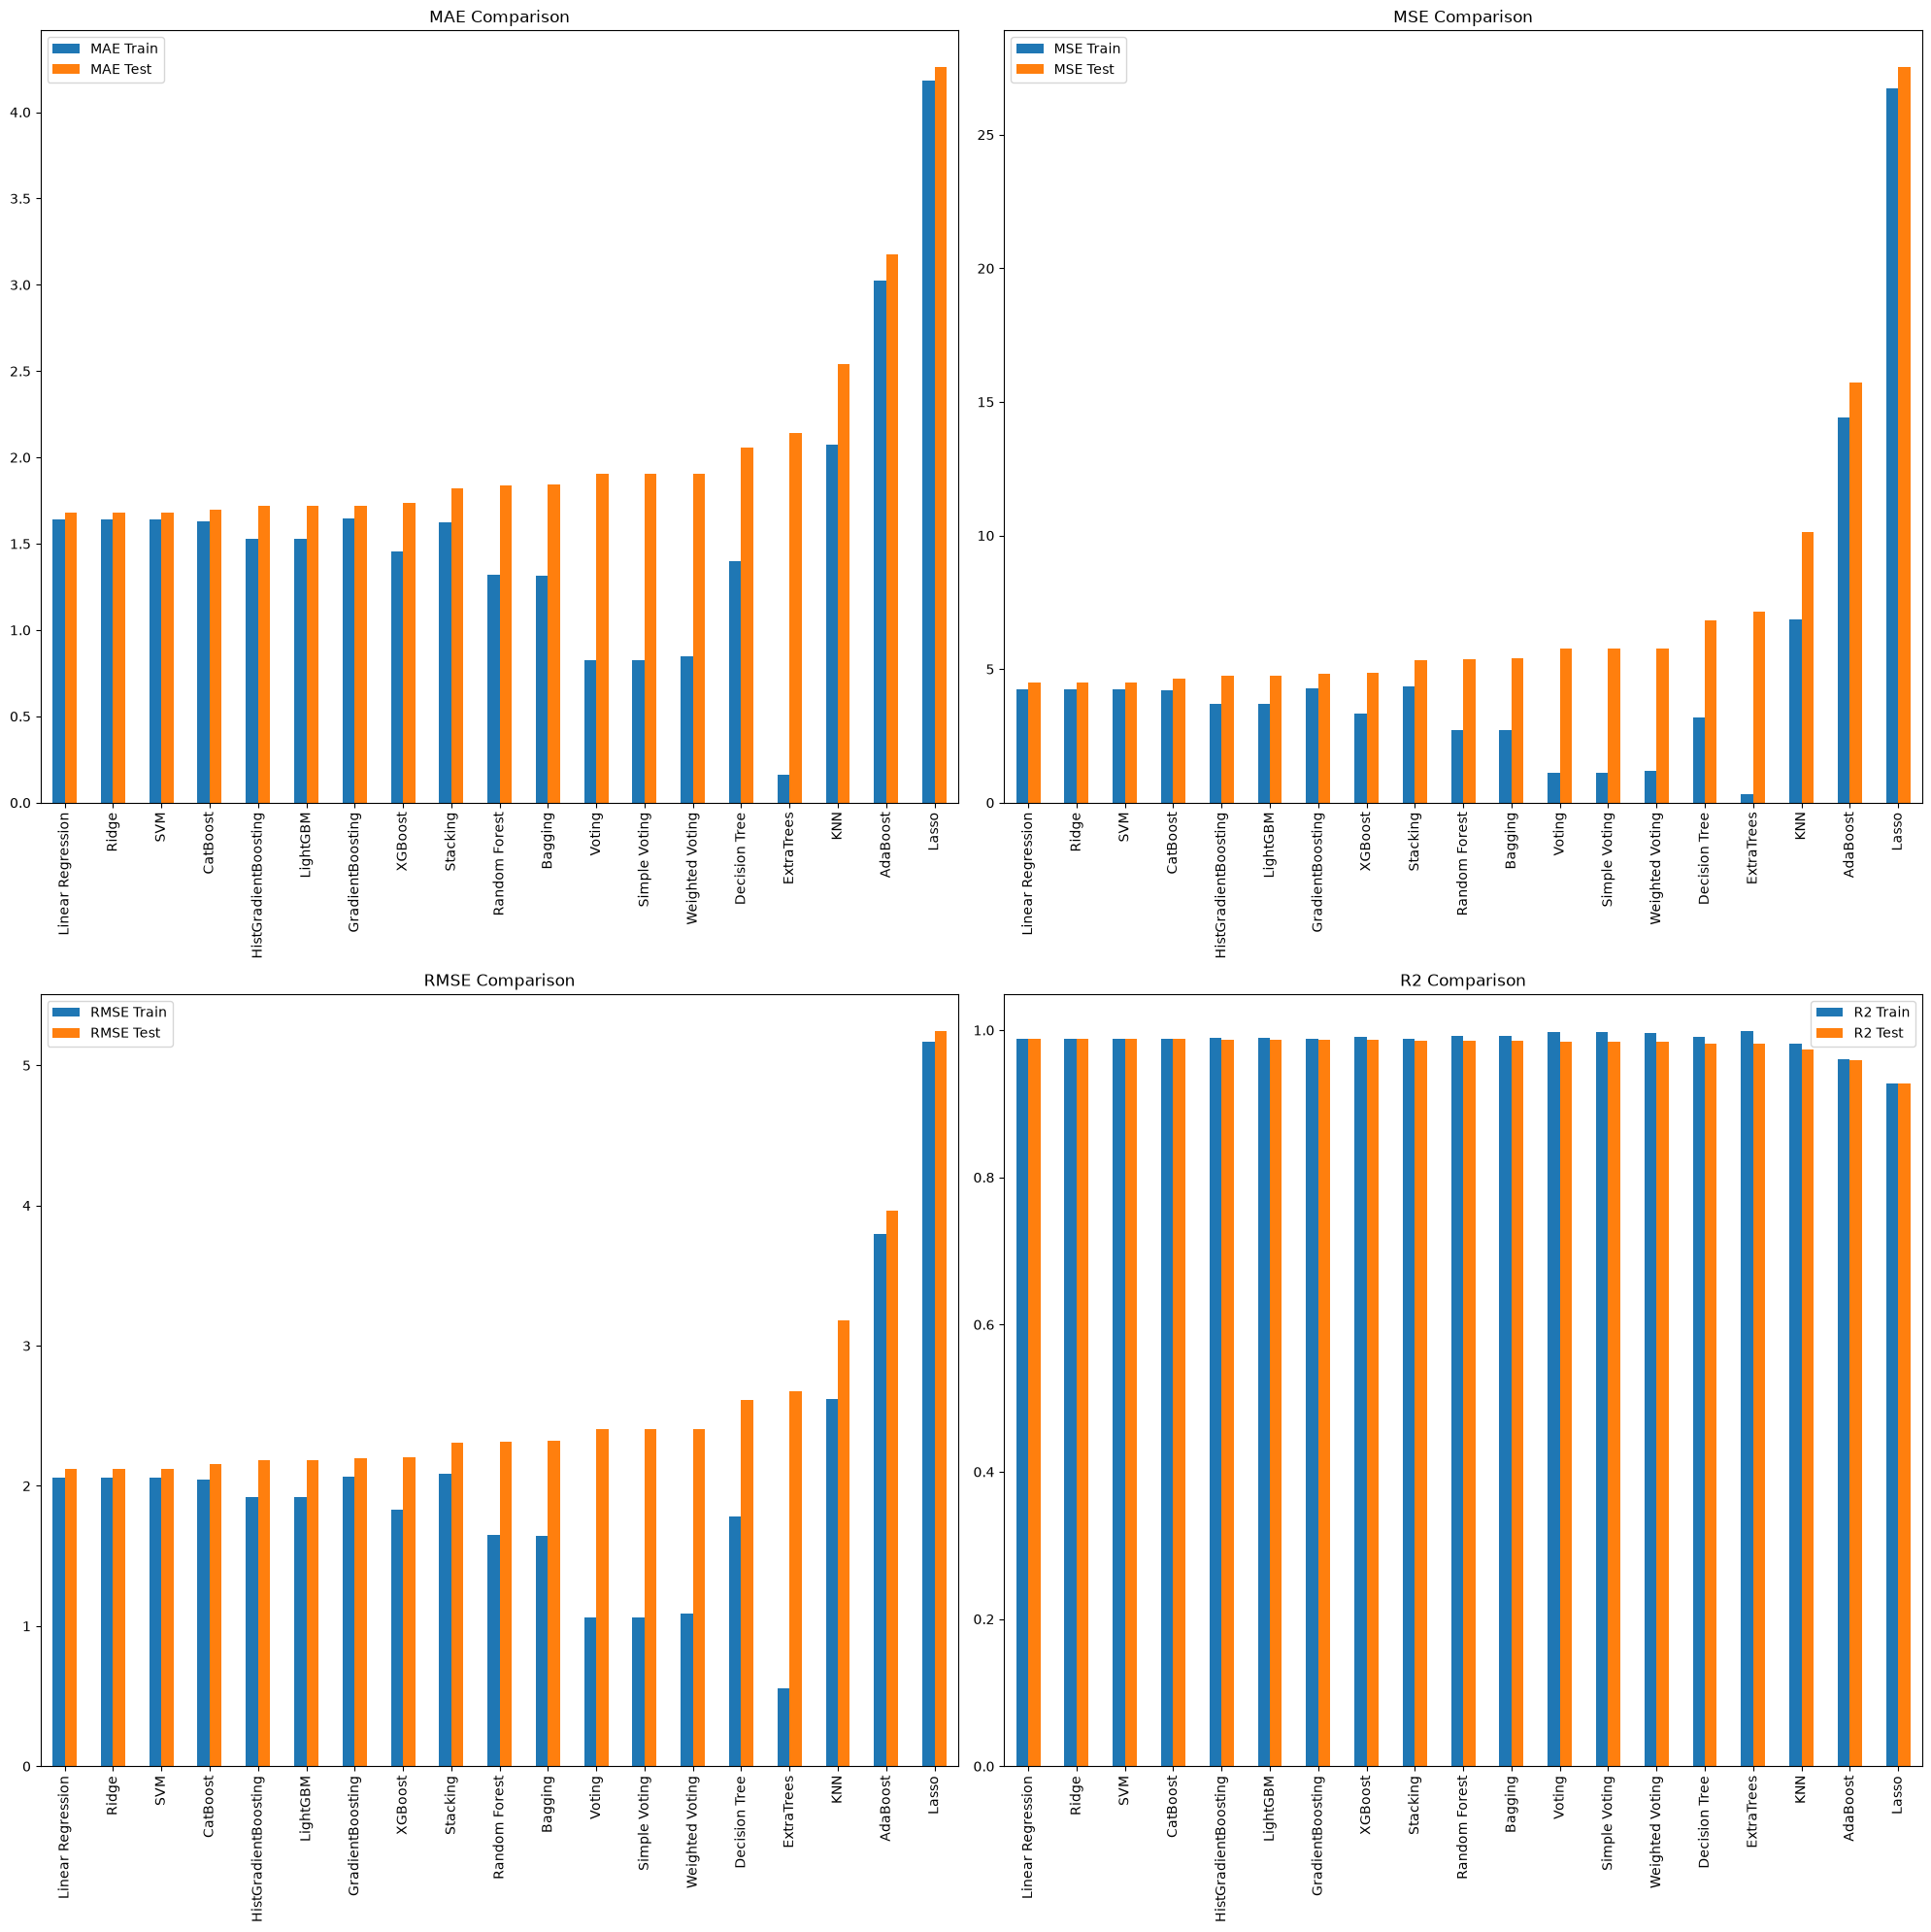

In [34]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20, 20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i + 1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()
